# Monte Carlo: demand shocks (CRS, FIGARO network)

Government buys a basket worth a share $G$ of baseline expenditure, $g=G\,w$ with $w$ a vector of shares summing to one, financed by a lump-sum tax. Under CRS prices stay at $1$ and
$$ y = L'\big[(1-G)\gamma + g\big]. $$
* **Crowding-out:** the goods leave the economy, $U=1-G$ for every allocation $w$ (no randomness).
* **Redistribution:** the goods are handed back to the household, $\ln U=\sum_i\gamma_i\ln\!\big[(1-G)+G\,w_i/\gamma_i\big]$, which depends on **how the purchase is allocated**.

The randomness here is therefore the **allocation** $w\sim\mathrm{Dirichlet}(\alpha\gamma)$: $\alpha\to\infty$ is the proportional basket ($w=\gamma$), small $\alpha$ concentrates the purchase on few sectors.

**What it does:** Monte Carlo over $(G,\alpha)$; welfare under redistribution vs crowding-out; output effects and sector-level propagation; single-sector purchases (welfare and output multiplier of every sector). Saves PNG/PDF figures and CSV/LaTeX tables in `mc_output/`.

**How to run:** put the FIGARO CSV next to the notebook, run all cells. Change `R` in section 1.

In [1]:
# ============================================================
# 0. SETUP  (identical in the three notebooks)
#    Loads FIGARO, builds A_model / gamma / beta, factorizes I-A once.
#    After the first run the model is cached on disk, so reloading is instant.
# ============================================================
from pathlib import Path
import re, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csc_matrix, eye, load_npz, save_npz
from scipy.sparse.linalg import splu

FILE_PATH = Path("matrix_eu-ic-io_ind-by-ind_26ed_2024_utf8.csv")
TARGET_INTERMEDIATE_SHARE = 0.99      # rescaling target for the 3 columns with beta <= 0
OUTPUT_DIR = Path("mc_output"); OUTPUT_DIR.mkdir(exist_ok=True)
A_CACHE, META_CACHE = Path("figaro_A_model.npz"), Path("figaro_meta.npz")

def build_model_from_csv():
    df = pd.read_csv(FILE_PATH, index_col="rowLabels", low_memory=False)
    num = df.apply(pd.to_numeric, errors="coerce")
    labs = [l for l in df.index if re.fullmatch(r"[A-Z]{2}_.+", str(l))
            and not str(l).startswith(("W2_", "FIGW1_")) and l in df.columns]
    x = num.loc[labs, :].sum(axis=1)
    active = x[x > 0].index.tolist()
    Z = num.loc[active, active].to_numpy(float)
    xa = x.loc[active].to_numpy(float)
    A = Z / xa[None, :]
    for j in np.where(1.0 - A.sum(axis=0) <= 0)[0]:          # columns with beta <= 0
        A[:, j] *= TARGET_INTERMEDIATE_SHARE / A[:, j].sum()
    p3 = [c for c in num.columns if str(c).endswith("_P3_S14")]
    hc = np.maximum(num.loc[active, p3].sum(axis=1).to_numpy(float), 0.0)
    return csc_matrix(A), hc / hc.sum(), np.array(active, dtype=str)

if A_CACHE.exists() and META_CACHE.exists() and float(np.load(META_CACHE)["target"]) == TARGET_INTERMEDIATE_SHARE:
    A_sparse = load_npz(A_CACHE).tocsc(); meta = np.load(META_CACHE)
    gamma, labels = meta["gamma"], meta["labels"]
    print("Loaded cached model.")
else:
    t0 = time.time(); A_sparse, gamma, labels = build_model_from_csv()
    save_npz(A_CACHE, A_sparse); np.savez(META_CACHE, gamma=gamma, labels=labels, target=TARGET_INTERMEDIATE_SHARE)
    print(f"Built model from CSV in {time.time()-t0:.0f}s and cached it.")

n = A_sparse.shape[0]
beta = 1.0 - np.asarray(A_sparse.sum(axis=0)).ravel()
I = eye(n, format="csc")
LU_M = splu((I - A_sparse).tocsc())          # solves with L' = (I-A)^{-1}
LU_T = splu((I - A_sparse.T).tocsc())        # solves with L^T = (I-A^T)^{-1}
v = LU_M.solve(gamma)                        # Domar weights  v = L' gamma
h = LU_T.solve(np.ones(n))                   # h_i = sum_j L'_{j,i}: output multiplier of final demand in sector i
sumv = v.sum()
country = np.array([l[:2] for l in labels]); countries, cidx = np.unique(country, return_inverse=True)
pos = gamma > 0
print(f"n = {n} sectors, {len(countries)} countries | sum(gamma) = {gamma.sum():.6f} | beta'v = {beta@v:.6f} | sum(v) = {sumv:.4f} | ||v||_2 = {np.linalg.norm(v):.4f}")

# ---------- small helpers ----------
COL = dict(co="#D55E00", red="#0072B2", grey="#6B6B6B", green="#009E73", purple="#CC79A7")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"{name}.png", dpi=200); fig.savefig(OUTPUT_DIR / f"{name}.pdf")
    plt.show()

def to_tex(df, name, float_fmt="{:.4f}", index=False):
    d = df.reset_index() if index else df
    cols = list(d.columns)
    lines = [r"\begin{tabular}{" + "l" * len(cols) + "}", r"\hline",
             " & ".join(str(c).replace("_", r"\_") for c in cols) + r" \\ \hline"]
    for _, r in d.iterrows():
        lines.append(" & ".join(float_fmt.format(r[c]) if isinstance(r[c], (float, np.floating))
                                else str(r[c]).replace("_", r"\_") for c in cols) + r" \\")
    lines += [r"\hline", r"\end{tabular}"]
    (OUTPUT_DIR / f"{name}.tex").write_text("\n".join(lines))
    d.to_csv(OUTPUT_DIR / f"{name}.csv", index=False)

def alab(a):  return "prop." if np.isinf(a) else str(int(a))

Built model from CSV in 5s and cached it.
n = 3070 sectors, 49 countries | sum(gamma) = 1.000000 | beta'v = 1.000000 | sum(v) = 1.8695 | ||v||_2 = 0.1569


In [2]:
# ============================================================
# 1. PARAMETERS
# ============================================================
SEED, R, BATCH = 2025, 2000, 250
GS = [0.01, 0.025, 0.05, 0.10, 0.20]            # government purchases as a share of baseline expenditure
ALPHAS = [np.inf, 1000, 100, 10, 1]             # Dirichlet concentration; inf = proportional to gamma
G_FOCUS = 0.05                                  # used in the single-G figures
SEC_R = 200                                     # draws for the (more expensive) sector-level analysis
rng = np.random.default_rng(SEED)

def draw_alloc(alpha, B):
    """Allocation shares w (columns sum to 1) with E[w]=gamma; only sectors with gamma>0 are purchased from."""
    if np.isinf(alpha): return np.tile(gamma[:, None], (1, B))
    W = np.zeros((n, B)); W[pos] = rng.gamma(shape=alpha * gamma[pos][:, None], size=(pos.sum(), B))
    return W / W.sum(0, keepdims=True)

hg = h @ gamma                                   # = sum(v): baseline total output
# ============================================================
# 2. MONTE CARLO OVER (G, alpha)
# ============================================================
rows, store = [], {}
t0 = time.time()
for alpha in ALPHAS:
    acc = {G: {k: [] for k in ["lnU_red", "dY", "neff"]} for G in GS}
    left = R
    while left > 0:
        B = min(BATCH, left); left -= B
        W = draw_alloc(alpha, B)
        neff = 1.0 / (W ** 2).sum(0)                              # effective number of sectors purchased from
        for G in GS:
            ratio = (1 - G) + G * W[pos] / gamma[pos][:, None]     # c_i/gamma_i under redistribution
            acc[G]["lnU_red"].append(gamma[pos] @ np.log(ratio))
            acc[G]["dY"].append(100 * G * (h @ W - hg) / hg)       # change in total output, % of baseline
            acc[G]["neff"].append(neff)
    for G in GS:
        d = pd.DataFrame({k: np.concatenate(vv) for k, vv in acc[G].items()}); store[(G, alpha)] = d
        U = np.exp(d.lnU_red.values)
        rows.append(dict(G=G, alpha=alab(alpha), U_crowding_out=1 - G, U_redistr_mean=U.mean(), U_redistr_q05=np.quantile(U, .05),
                         U_redistr_q95=np.quantile(U, .95), loss_ratio_mean=(1 - U).mean() / G, mean_dY_pct=d.dY.mean(),
                         std_dY_pct=d.dY.std(), mean_eff_sectors=d.neff.mean()))
    print(f"alpha={alab(alpha)} done ({time.time()-t0:.0f}s)")
stats = pd.DataFrame(rows)
to_tex(stats, "demand_mc_stats", "{:.4f}"); print(stats.round(4).to_string(index=False))

# ============================================================
# 3. SECTOR-LEVEL PROPAGATION at G_FOCUS (does the purchase raise suppliers' output?)
# ============================================================
sec_rows = []; dY_example = {}
for alpha in ALPHAS:
    W = draw_alloc(alpha, SEC_R)
    dy = LU_M.solve(G_FOCUS * (W - gamma[:, None]))                # change in sector output (levels), n x SEC_R
    rel = dy / v[:, None]
    direct = (G_FOCUS * W) > 1e-6                                  # sectors the government buys from directly
    gain_total = np.where(dy > 0, dy, 0).sum(0)
    indirect_gain = np.where((dy > 0) & ~direct, dy, 0).sum(0)
    sec_rows.append(dict(alpha=alab(alpha), frac_sectors_up=(dy > 1e-15).mean(), frac_sectors_down=(dy < -1e-15).mean(),
                         frac_up_by_more_than_1pct=(rel > .01).mean(), frac_down_by_more_than_1pct=(rel < -.01).mean(),
                         share_of_gross_gain_in_indirectly_reached_sectors=np.nanmean(indirect_gain / np.maximum(gain_total, 1e-300)),
                         max_abs_rel_change_pct=100 * np.abs(rel).max(0).mean()))
sec = pd.DataFrame(sec_rows); to_tex(sec, "demand_sector_propagation", "{:.4f}"); print(f"\nSector-level effects at G={G_FOCUS}:"); print(sec.round(4).to_string(index=False))

# ============================================================
# 4. SINGLE-SECTOR PURCHASES: every sector j in turn (deterministic, exact)
# ============================================================
Gs_ = G_FOCUS
ln_red_j = np.full(n, np.nan)
ln_red_j[pos] = (1 - gamma[pos]) * np.log(1 - Gs_) + gamma[pos] * np.log(1 - Gs_ + Gs_ / gamma[pos])
mult = h - sumv                                   # d(total output)/dG when the government buys only from sector j
single = pd.DataFrame(dict(sector=labels, gamma=gamma, v=v, multiplier=mult, lnU_redistribution=ln_red_j))
print(f"\nSingle-sector purchase, G={G_FOCUS}: crowding-out lnU = {np.log(1-G_FOCUS):.4f} for every sector.")
print(single.sort_values("multiplier", ascending=False).head(15).round(5).to_string(index=False))
to_tex(single.sort_values("multiplier", ascending=False).head(20), "demand_top_multipliers", "{:.5g}")

alpha=prop. done (1s)
alpha=1000 done (2s)
alpha=100 done (4s)
alpha=10 done (5s)
alpha=1 done (7s)
    G alpha  U_crowding_out  U_redistr_mean  U_redistr_q05  U_redistr_q95  loss_ratio_mean  mean_dY_pct  std_dY_pct  mean_eff_sectors
0.010 prop.           0.990          1.0000         1.0000         1.0000           0.0000      -0.0000      0.0000           85.5945
0.025 prop.           0.975          1.0000         1.0000         1.0000           0.0000      -0.0000      0.0000           85.5945
0.050 prop.           0.950          1.0000         1.0000         1.0000           0.0000      -0.0000      0.0000           85.5945
0.100 prop.           0.900          1.0000         1.0000         1.0000           0.0000      -0.0000      0.0000           85.5945
0.200 prop.           0.800          1.0000         1.0000         1.0000           0.0000      -0.0000      0.0000           85.5945
0.010  1000           0.990          0.9999         0.9999         0.9999           0.0094      

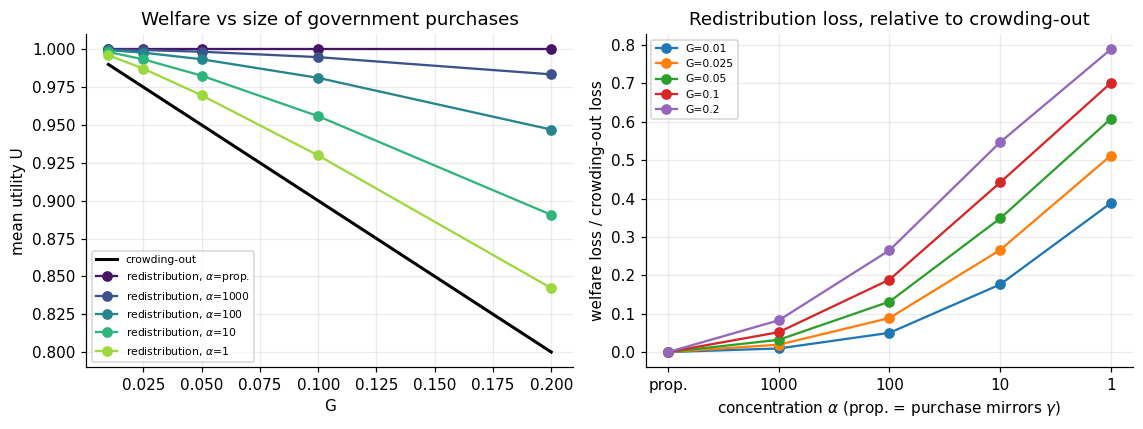

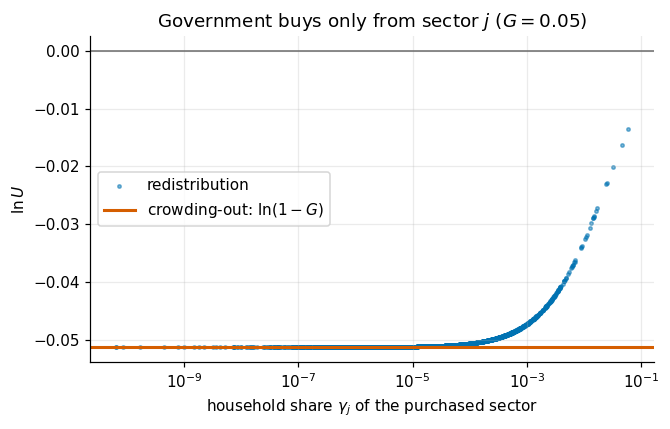

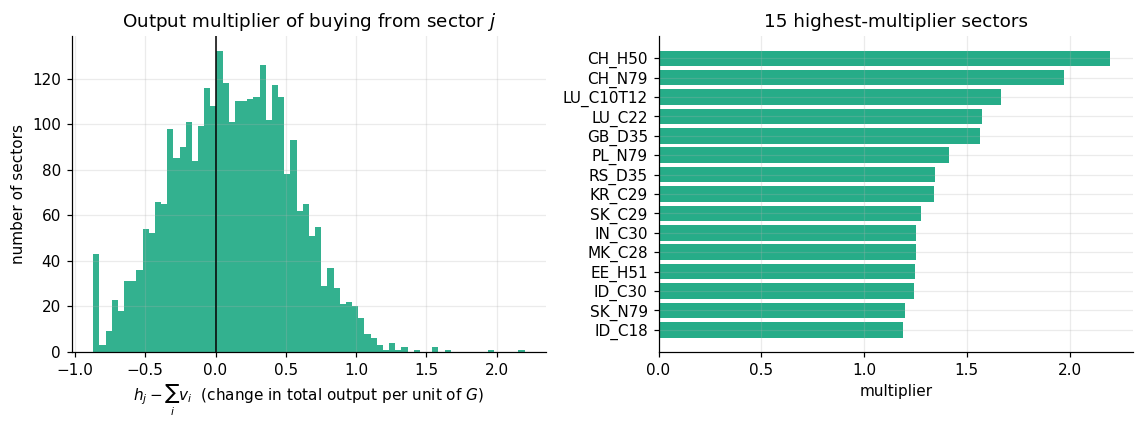

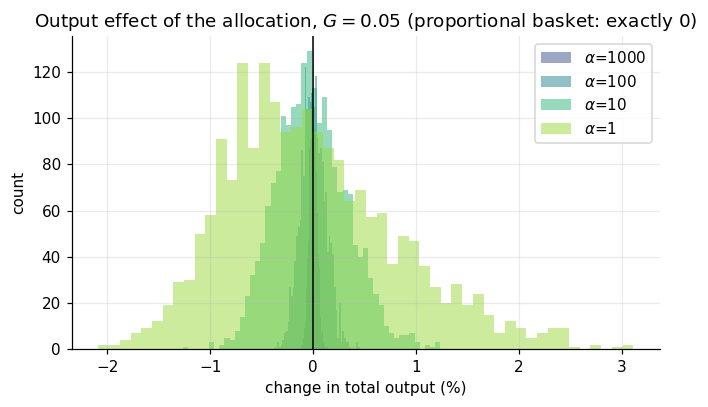

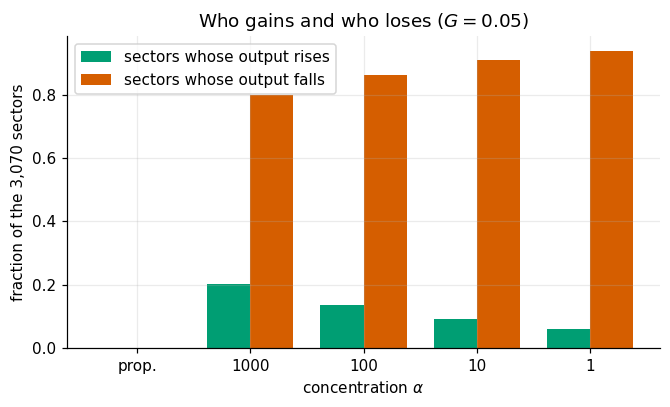


All outputs saved in /content/mc_output


In [3]:
# ============================================================
# 5. FIGURES
# ============================================================
cols = plt.cm.viridis(np.linspace(0.05, 0.85, len(ALPHAS)))
# Fig 1 - welfare vs G, and loss relative to crowding-out
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4))
Gg = np.array(GS); axs[0].plot(Gg, 1 - Gg, "k-", lw=2, label="crowding-out")
for a, c in zip(ALPHAS, cols):
    m = np.array([store[(G, a)].lnU_red.pipe(lambda s: np.exp(s).mean()) for G in GS]); axs[0].plot(Gg, m, "o-", color=c, label=rf"redistribution, $\alpha$={alab(a)}")
axs[0].set_xlabel("G"); axs[0].set_ylabel("mean utility U"); axs[0].set_title("Welfare vs size of government purchases"); axs[0].legend(fontsize=7)
for G in GS:
    axs[1].plot(range(len(ALPHAS)), [(1 - np.exp(store[(G, a)].lnU_red)).mean() / G for a in ALPHAS], "o-", label=f"G={G}")
axs[1].set_xticks(range(len(ALPHAS))); axs[1].set_xticklabels([alab(a) for a in ALPHAS]); axs[1].set_xlabel(r"concentration $\alpha$ (prop. = purchase mirrors $\gamma$)")
axs[1].set_ylabel("welfare loss / crowding-out loss"); axs[1].set_title("Redistribution loss, relative to crowding-out"); axs[1].legend(fontsize=7)
savefig(fig, "dem_fig1_welfare")

# Fig 2 - single-sector purchases: welfare depends on how much the household values the good
fig, ax = plt.subplots(figsize=(6.2, 4))
ax.scatter(gamma[pos], ln_red_j[pos], s=5, color=COL["red"], alpha=.5, label="redistribution")
ax.axhline(np.log(1 - G_FOCUS), color=COL["co"], lw=2, label=r"crowding-out: $\ln(1-G)$"); ax.axhline(0, color=COL["grey"], lw=1)
ax.set_xscale("log"); ax.set_xlabel(r"household share $\gamma_j$ of the purchased sector"); ax.set_ylabel(r"$\ln U$")
ax.set_title(rf"Government buys only from sector $j$ ($G={G_FOCUS}$)"); ax.legend(); savefig(fig, "dem_fig2_single_sector_welfare")

# Fig 3 - output multipliers
fig, axs = plt.subplots(1, 2, figsize=(10.5, 4))
axs[0].hist(mult, bins=70, color=COL["green"], alpha=.8); axs[0].axvline(0, color="k", lw=1)
axs[0].set_xlabel(r"$h_j-\sum_i v_i$  (change in total output per unit of $G$)"); axs[0].set_ylabel("number of sectors"); axs[0].set_title("Output multiplier of buying from sector $j$")
tp = single.sort_values("multiplier", ascending=False).head(15).iloc[::-1]
axs[1].barh(tp.sector, tp.multiplier, color=COL["green"], alpha=.85); axs[1].set_title("15 highest-multiplier sectors"); axs[1].set_xlabel("multiplier")
savefig(fig, "dem_fig3_multipliers")

# Fig 4 - total output effect of the allocation
fig, ax = plt.subplots(figsize=(6.2, 3.8))
for a, c in zip(ALPHAS[1:], cols[1:]):
    ax.hist(store[(G_FOCUS, a)].dY, bins=50, alpha=.5, color=c, label=rf"$\alpha$={alab(a)}")
ax.axvline(0, color="k", lw=1); ax.set_xlabel("change in total output (%)"); ax.set_ylabel("count")
ax.set_title(rf"Output effect of the allocation, $G={G_FOCUS}$ (proportional basket: exactly 0)"); ax.legend(); savefig(fig, "dem_fig4_output_effect")

# Fig 5 - sector-level propagation
fig, ax = plt.subplots(figsize=(6.2, 3.8)); xi = np.arange(len(ALPHAS)); w = .38
ax.bar(xi - w/2, sec.frac_sectors_up, w, color=COL["green"], label="sectors whose output rises")
ax.bar(xi + w/2, sec.frac_sectors_down, w, color=COL["co"], label="sectors whose output falls")
ax.set_xticks(xi); ax.set_xticklabels(sec.alpha); ax.set_xlabel(r"concentration $\alpha$"); ax.set_ylabel("fraction of the 3,070 sectors")
ax.set_title(rf"Who gains and who loses ($G={G_FOCUS}$)"); ax.legend(); savefig(fig, "dem_fig5_sector_propagation")
print("\nAll outputs saved in", OUTPUT_DIR.resolve())